# Champion v2 — fixing and re-benchmarking the forecaster

**Goal:** rebuild the t+1…t+3 Max/Min temperature forecaster on honest footing.

What changes vs `champion_model_phase1`:
1. **Baselines first** — persistence, climatology and damped anomaly persistence. A model only counts if it beats these.
2. **Today's temperatures are features** (lag 0). Phase 1 only saw yesterday.
3. **Anomaly target** — predict deviation from a smoothed day-of-year climatology (fit on training years only), then add climatology back.
4. **No `Year` feature** — trees can't extrapolate it past the training period.
5. **One model per horizon × variable**, tuned with `TimeSeriesSplit`, MAE objective.
6. **Skill vs persistence, by season**, reported for every model.

Test period is unchanged (from 2019-08-26) so results are directly comparable with Phase 1.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, joblib, warnings
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error
warnings.filterwarnings('ignore')

ROOT = Path('..') if Path('../data').exists() else Path('.')
DATA = ROOT / 'data' / 'df_analysis.csv'
OUT_MODELS = ROOT / 'models'; OUT_MODELS.mkdir(exist_ok=True)
OUT_IMG = ROOT / 'images'; OUT_IMG.mkdir(exist_ok=True)

TEST_START = pd.Timestamp('2019-08-26')   # same split as Phase 1
HORIZONS = [1, 2, 3]
VARS = {'Max': 'Max_Temp_C', 'Min': 'Min_Temp_C'}
SEED = 42

## 1. Load data

In [2]:
df = pd.read_csv(DATA)
df['Date'] = pd.to_datetime(df['Year'].astype(str) + '-' + df['Day_of_Year'].astype(str), format='%Y-%j')
df = df.set_index('Date').sort_index()
gaps = len(pd.date_range(df.index.min(), df.index.max())) - len(df)
print(f'{len(df)} days, {df.index.min().date()} → {df.index.max().date()}, missing days: {gaps}')

9422 days, 1999-01-01 → 2024-10-17, missing days: 0


## 2. Climatology (training years only)
Mean Max/Min for each day of year, smoothed with a 31-day circular window. Fit on pre-test data only, so no test information leaks into the target.

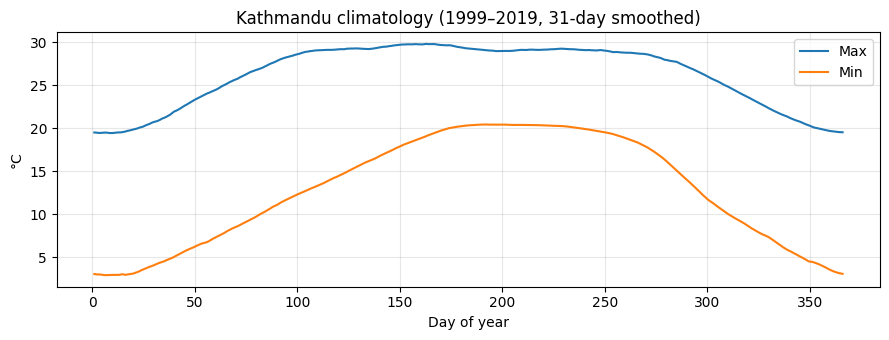

In [3]:
train_raw = df[df.index < TEST_START]
clim = train_raw.groupby('Day_of_Year')[list(VARS.values())].mean().reindex(range(1, 367)).interpolate()
pad = 15
clim = pd.concat([clim.iloc[-pad:], clim, clim.iloc[:pad]]).rolling(2*pad+1, center=True).mean().iloc[pad:-pad]
clim.index = range(1, 367)

for k, col in VARS.items():
    df[f'clim_{k}'] = clim[col].reindex(df['Day_of_Year']).values
    df[f'anom_{k}'] = df[col] - df[f'clim_{k}']

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(clim.index, clim['Max_Temp_C'], label='Max'); ax.plot(clim.index, clim['Min_Temp_C'], label='Min')
ax.set(xlabel='Day of year', ylabel='°C', title='Kathmandu climatology (1999–2019, 31-day smoothed)'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT_IMG / 'v2_climatology.png', dpi=120); plt.show()

## 3. Features
Everything is known at the end of day *t* — no future information.

In [4]:
P = df['Precipitation_mm']
for k in VARS:
    a = df[f'anom_{k}']
    for L in [0, 1, 2, 3, 7]:
        df[f'anom_{k}_lag{L}'] = a.shift(L)
    for w in [3, 7, 30]:
        df[f'anom_{k}_mean{w}'] = a.rolling(w).mean()
    df[f'anom_{k}_std7'] = a.rolling(7).std()
    df[f'anom_{k}_diff1'] = a.diff()
for L in [0, 1, 2, 3]:
    df[f'precip_lag{L}'] = P.shift(L)
for w in [3, 7, 30]:
    df[f'precip_sum{w}'] = P.rolling(w).sum()
df['rain_today'] = (P > 0.1).astype(int)
df['dtr'] = df['Max_Temp_C'] - df['Min_Temp_C']
df['dtr_mean7'] = df['dtr'].rolling(7).mean()

FEATURES = [c for c in df.columns if c.startswith(('anom_Max_', 'anom_Min_', 'precip_', 'rain_', 'dtr'))] \
           + ['Day_of_Year_sin', 'Day_of_Year_cos']
print(len(FEATURES), 'features')

32 features


## 4. Targets and split

In [5]:
for h in HORIZONS:
    for k, col in VARS.items():
        df[f'y_{k}_t{h}'] = df[col].shift(-h)            # actual future temp
        df[f'yanom_{k}_t{h}'] = df[f'anom_{k}'].shift(-h) # model target
        df[f'clim_{k}_t{h}'] = df[f'clim_{k}'].shift(-h)  # added back after prediction

target_cols = [c for c in df.columns if c.startswith(('y_', 'yanom_', 'clim_Max_t', 'clim_Min_t'))]
data = df.dropna(subset=FEATURES + target_cols)
train, test = data[data.index < TEST_START], data[data.index >= TEST_START]
print(f'train {train.index.min().date()}→{train.index.max().date()} ({len(train)}) | test {test.index.min().date()}→{test.index.max().date()} ({len(test)})')

train 1999-01-30→2019-08-25 (7513) | test 2019-08-26→2024-10-14 (1877)


## 5. Baselines
- **Persistence:** tomorrow = today.
- **Climatology:** tomorrow = the long-term average for that date.
- **Damped anomaly persistence:** climatology + α^h × today's anomaly, α fit on training data. A stronger, still trivial, baseline.

In [6]:
def season(m):
    return np.select([m.isin([12,1,2]), m.isin([3,4,5]), m.isin([6,7,8,9])],
                     ['Winter','Pre-monsoon','Monsoon'], 'Post-monsoon')
test_season = pd.Series(season(test.index.month), index=test.index)

def mae(a, b): return mean_absolute_error(a, b)
def rmse(a, b): return np.sqrt(mean_squared_error(a, b))

preds = {}  # (model, var, h) -> Series
for k, col in VARS.items():
    a_tr = train[f'anom_{k}'];  alpha = np.corrcoef(a_tr[:-1], a_tr[1:])[0, 1]
    print(f'{k}: lag-1 anomaly autocorrelation α = {alpha:.3f}')
    for h in HORIZONS:
        preds[('Persistence', k, h)] = test[col]
        preds[('Climatology', k, h)] = test[f'clim_{k}_t{h}']
        preds[('Damped persistence', k, h)] = test[f'clim_{k}_t{h}'] + alpha**h * test[f'anom_{k}']

Max: lag-1 anomaly autocorrelation α = 0.610
Min: lag-1 anomaly autocorrelation α = 0.617


## 6. Champion v2 — XGBoost, one model per horizon × variable
Tuned with `RandomizedSearchCV` over a 5-fold `TimeSeriesSplit` on training data only, MAE objective.

In [7]:
param_dist = {
    'n_estimators': [300, 500, 800, 1200],
    'learning_rate': [0.01, 0.02, 0.05],
    'max_depth': [2, 3, 4, 5],
    'min_child_weight': [1, 5, 10, 20],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_lambda': [1, 5, 10],
}
tscv = TimeSeriesSplit(n_splits=5)
models, best_params = {}, {}
for k in VARS:
    for h in HORIZONS:
        search = RandomizedSearchCV(
            xgb.XGBRegressor(objective='reg:absoluteerror', random_state=SEED, n_jobs=-1),
            param_dist, n_iter=20, cv=tscv, scoring='neg_mean_absolute_error', random_state=SEED, n_jobs=1)
        search.fit(train[FEATURES], train[f'yanom_{k}_t{h}'])
        m = search.best_estimator_
        models[(k, h)] = m; best_params[(k, h)] = search.best_params_
        preds[('Champion v2', k, h)] = pd.Series(m.predict(test[FEATURES]), index=test.index) + test[f'clim_{k}_t{h}']
        print(f'{k} t+{h}: CV MAE {-search.best_score_:.3f} | {search.best_params_}')

Max t+1: CV MAE 1.178 | {'subsample': 0.7, 'reg_lambda': 5, 'n_estimators': 800, 'min_child_weight': 20, 'max_depth': 2, 'learning_rate': 0.02, 'colsample_bytree': 0.8}


Max t+2: CV MAE 1.390 | {'subsample': 0.7, 'reg_lambda': 5, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 2, 'learning_rate': 0.05, 'colsample_bytree': 0.8}


Max t+3: CV MAE 1.489 | {'subsample': 0.7, 'reg_lambda': 10, 'n_estimators': 500, 'min_child_weight': 10, 'max_depth': 2, 'learning_rate': 0.02, 'colsample_bytree': 0.8}


Min t+1: CV MAE 0.941 | {'subsample': 0.7, 'reg_lambda': 5, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 2, 'learning_rate': 0.05, 'colsample_bytree': 0.8}


Min t+2: CV MAE 1.090 | {'subsample': 0.8, 'reg_lambda': 5, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.02, 'colsample_bytree': 0.6}


Min t+3: CV MAE 1.159 | {'subsample': 0.8, 'reg_lambda': 5, 'n_estimators': 800, 'min_child_weight': 20, 'max_depth': 2, 'learning_rate': 0.01, 'colsample_bytree': 0.6}


## 7. Results vs baselines (and Phase 1)

In [8]:
PHASE1 = {('Max',1):1.34, ('Min',1):0.94, ('Max',2):1.52, ('Min',2):1.05, ('Max',3):1.59, ('Min',3):1.09}
rows = []
for (name, k, h), p in preds.items():
    y = test[f'y_{k}_t{h}']
    rows.append({'Model': name, 'Var': k, 'h': h, 'MAE': mae(y, p), 'RMSE': rmse(y, p)})
res = pd.DataFrame(rows)
for (k, h), v in PHASE1.items():
    res.loc[len(res)] = {'Model': 'Phase 1 champion (reported)', 'Var': k, 'h': h, 'MAE': v, 'RMSE': np.nan}
pers = res[res.Model == 'Persistence'].set_index(['Var', 'h'])['MAE']
res['Skill vs persistence'] = 1 - res['MAE'] / res.set_index(['Var', 'h']).index.map(pers).values
table = res.pivot_table(index='Model', columns=['Var', 'h'], values='MAE').round(2)
order = ['Climatology', 'Persistence', 'Damped persistence', 'Phase 1 champion (reported)', 'Champion v2']
table = table.loc[order]
print('MAE (°C) on test set'); display(table)
skill = res.pivot_table(index='Model', columns=['Var', 'h'], values='Skill vs persistence').loc[order]
print('Skill vs persistence (1 − MAE/MAE_persistence; >0 = better)'); display((skill*100).round(1).astype(str) + '%')

MAE (°C) on test set


Var                           Max               Min            
h                               1     2     3     1     2     3
Model                                                          
Climatology                  1.82  1.82  1.82  1.34  1.34  1.34
Persistence                  1.39  1.71  1.94  0.91  1.14  1.26
Damped persistence           1.31  1.56  1.67  0.89  1.09  1.19
Phase 1 champion (reported)  1.34  1.52  1.59  0.94  1.05  1.09
Champion v2                  1.24  1.45  1.56  0.85  1.05  1.16

Skill vs persistence (1 − MAE/MAE_persistence; >0 = better)


Var                             Max                   Min               
h                                 1      2      3       1       2      3
Model                                                                   
Climatology                  -31.3%  -6.2%   6.5%  -47.5%  -17.7%  -6.6%
Persistence                    0.0%   0.0%   0.0%    0.0%    0.0%   0.0%
Damped persistence             5.6%   9.0%  14.0%    2.5%    4.8%   5.6%
Phase 1 champion (reported)    3.3%  11.3%  18.2%   -3.1%    8.1%  13.6%
Champion v2                   10.8%  15.5%  19.8%    6.8%    8.4%   8.2%

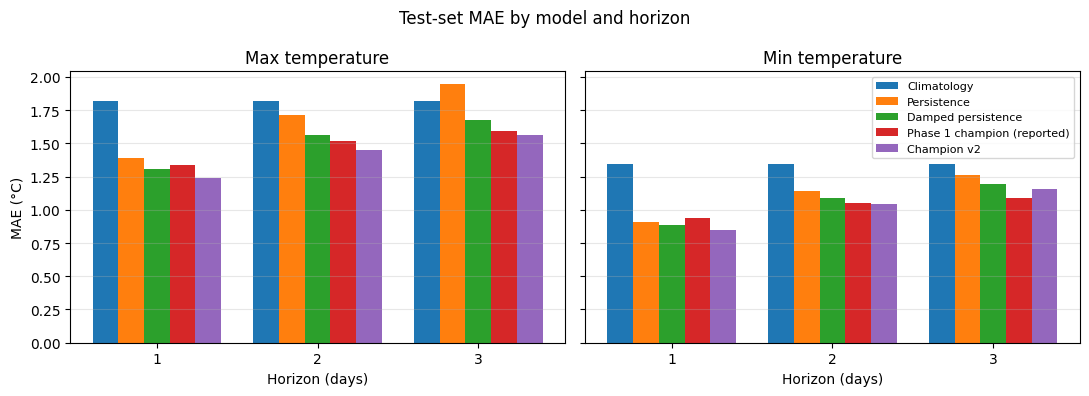

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, k in zip(axes, VARS):
    sub = res[(res.Var == k) & res.Model.isin(order)]
    w = 0.16
    for i, name in enumerate(order):
        s = sub[sub.Model == name].sort_values('h')
        ax.bar(np.array(HORIZONS) + (i - 2) * w, s['MAE'], w, label=name)
    ax.set(title=f'{k} temperature', xlabel='Horizon (days)', xticks=HORIZONS); ax.grid(axis='y', alpha=.3)
axes[0].set_ylabel('MAE (°C)'); axes[1].legend(fontsize=8)
plt.suptitle('Test-set MAE by model and horizon'); plt.tight_layout()
plt.savefig(OUT_IMG / 'v2_mae_by_model.png', dpi=120); plt.show()

## 8. Where does it work? Skill by season (t+1)

In [10]:
rows = []
for k in VARS:
    y = test[f'y_{k}_t1']
    for s in ['Winter', 'Pre-monsoon', 'Monsoon', 'Post-monsoon']:
        idx = test_season == s
        m_p = mae(y[idx], preds[('Persistence', k, 1)][idx]); m_c = mae(y[idx], preds[('Champion v2', k, 1)][idx])
        rows.append({'Var': k, 'Season': s, 'Days': int(idx.sum()), 'Persistence MAE': round(m_p, 2),
                     'Champion v2 MAE': round(m_c, 2), 'Skill': f'{(1 - m_c/m_p)*100:.1f}%'})
seasonal = pd.DataFrame(rows); display(seasonal)

,Var,Season,Days,Persistence MAE,Champion v2 MAE,Skill
0,Max,Winter,452,1.21,1.14,6.0%
1,Max,Pre-monsoon,460,1.57,1.40,10.6%
2,Max,Monsoon,646,1.57,1.36,13.3%
3,Max,Post-monsoon,319,1.00,0.89,11.4%
4,Min,Winter,452,0.98,0.98,-1.0%
5,Min,Pre-monsoon,460,1.18,1.08,7.8%
6,Min,Monsoon,646,0.70,0.58,16.6%
7,Min,Post-monsoon,319,0.87,0.86,1.5%


## 9. What drives the forecast? (t+1 Max)

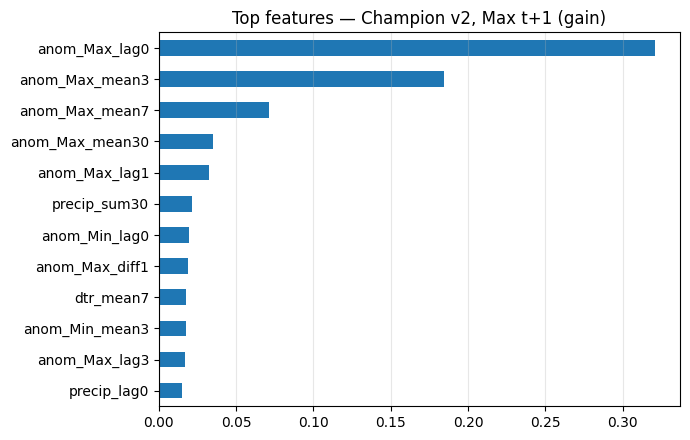

In [11]:
imp = pd.Series(models[('Max', 1)].feature_importances_, index=FEATURES).sort_values().tail(12)
imp.plot.barh(figsize=(7, 4.5), title='Top features — Champion v2, Max t+1 (gain)'); plt.grid(axis='x', alpha=.3)
plt.tight_layout(); plt.savefig(OUT_IMG / 'v2_feature_importance_max_t1.png', dpi=120); plt.show()

## 10. Residual check

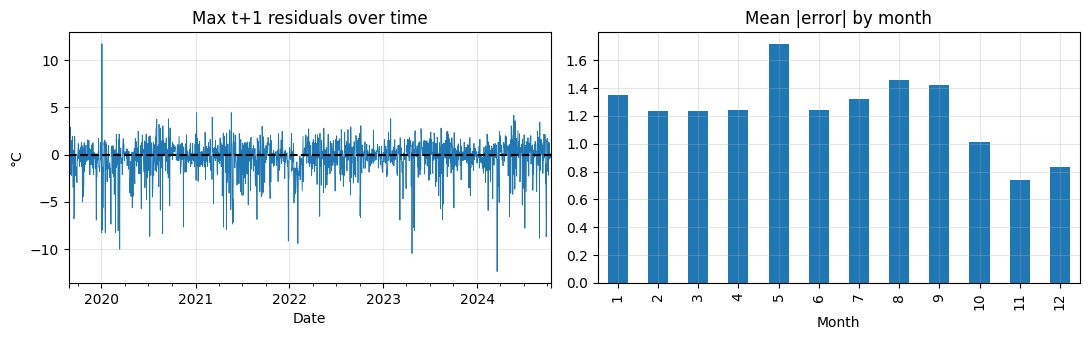

Mean bias: -0.34 °C


In [12]:
r = test['y_Max_t1'] - preds[('Champion v2', 'Max', 1)]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
r.plot(ax=axes[0], lw=.6); axes[0].axhline(0, c='k', ls='--'); axes[0].set(title='Max t+1 residuals over time', ylabel='°C')
r.groupby(r.index.month).apply(lambda x: x.abs().mean()).plot.bar(ax=axes[1], title='Mean |error| by month', xlabel='Month')
for ax in axes: ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(OUT_IMG / 'v2_residuals_max_t1.png', dpi=120); plt.show()
print(f'Mean bias: {r.mean():+.2f} °C')

## 11. Save the models
Each model is saved in XGBoost's native JSON format (portable across versions and operating systems), with the feature list and climatology alongside — the live forecaster needs all three.

In [13]:
import sys; sys.path.insert(0, str(ROOT))
from src.model_io import save_temp_models
save_temp_models(models, FEATURES, clim, {'test_start': str(TEST_START.date()), 'best_params': {f'{k}_t{h}': v for (k, h), v in best_params.items()}})

Saved 6 models to ../models/champion_v2


## 12. Next step
Quantile XGBoost (10th / 50th / 90th percentile) on the same features, to replace the binary confidence classifier with a forecast range.